# Polymerfolding med Monte Carlo-simulering

In [15]:
import random
import time
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps as cm
from scipy.spatial import distance

def helloworld(self):
    return(self(helloworld.__name__))


helloworld(print)

helloworld


I biofysikk står studiet av proteiner, enzymer og DNA sentralt. For å beskrive disse bioploymerenes konfigurasjon må strukturen og egenskaper til polymerer forstås. Polymerer består av underenheter, monomerer, som vekselvirker med hverandre og dermed bestemmer strukturen til polymerene. Dette kan sammenliknes med proteiners oppbygning som lange kjeder av aminosyrer. Strukturen til polymerene bestemmer egenskapene og feilfolding kan føre til sykdommer som Parkinsin's sykdom. Å analysere polymerstruktur er derfor et viktig studieområde.

For å fremstille en polymer på mest hensiktsmessig måte definerer vi hver monomer som en vektor. Polymeren blir dermed et to-dimensjonalt numpy-array bestående av N vektorer. Vektorene har en x- og en y-koordinat som plasserer monomerene i fohold til hverandre.

Lager først utgangspolymer med lengde N som legger seg horisontalt langs x-aksen.

In [3]:
init_polymer = lambda N: np.array([[i + 1, 0] for i in range(N)]) # Initialize polymer function
N0 = 30 # length
p0 = init_polymer(N0) # base- polymer with length 30

Dersom vi forsøker å rotere om endepunktene vil hele polymeren rotere. Det vil si at polymerstrukturen ikke endrer seg, men peker kun i en annen retning i rommet. Energien vil ikke endre seg fordi det ikke kan dannes noen nye svake bindinger mellom monomerer. Det vil derfor ikke være hensiktsmessig å inkludere endemonomerene i utvalget den tilfeldige rotasjonsmonomeren trekkes fra, ettersom det ikke fører til noen interessant endring av polymeren.

For å visualisere polymeren lages et grid som formes utifra polymerens endelige struktur. Hver monomer får en unik farge og tall.

In [13]:
# Function to convert the 2D vector representation of a polymer to a grid
def convert_to_grid(polymer):
    # Shift the polymer to positive axes
    min_x = polymer[:, 0].min()
    min_y = polymer[:, 1].min()

    # Find the minimum x and y values
    shift_x = -min_x if min_x < 0 else 0
    shift_y = -min_y if min_y < 0 else 0

    # Adjust the polymer to the origin
    adjusted_polymer = polymer + np.array([shift_x, shift_y])

    # Determine the new size of the grid for the polymer
    max_x = adjusted_polymer[:, 0].max()
    max_y = adjusted_polymer[:, 1].max()
    grid_size_x = max_x + 1
    grid_size_y = max_y + 1

    # Create a new grid
    grid = np.zeros((grid_size_y, grid_size_x), dtype=int)

    # Place the polymer in the grid with unique IDs <= i + 1 <= N
    for i, point in enumerate(adjusted_polymer):
        x, y = point
        grid[y, x] = i + 1

    # Cleaning up polymer grid of all 0 rows and columns
    grid = grid[~np.all(grid == 0, axis=1)]
    grid = grid[:, ~np.all(grid == 0, axis=0)]
    return grid


def plot(ax, polymer_2d, cmap_name="plasma"):
    # Convert the 2D vector polymer to a grid
    polymer = convert_to_grid(polymer_2d)

    # Mask zeros in the polymer grid
    polymer_masked = np.ma.masked_where(polymer == 0, polymer)

    # Create a colormap and set the masked values to white
    cmap = cm.get_cmap(cmap_name).copy()
    cmap.set_bad(color="white")
    
    nx, ny = polymer_masked.shape

    # Plot the polymer on the provided axis
    c = ax.pcolormesh(polymer_masked, cmap=cmap, linewidth=0.5, antialiased=True)
    for i in range(nx):
        for j in range(ny):
            val = polymer_masked[i, j]
            if val != 0:
                ax.text(j + 0.5, i + 0.5, f"{val:.0f}", ha="center", va="center", color="black")

    # Add a colorbar
    cbar = plt.colorbar(c, ax=ax)
    cbar.set_label(f'$m_i$')
    cmap.set_under('mistyrose')
    # Adjust the plot settings
    ax.set_title('Polymer')
    ax.set_xticks([], minor=True)
    ax.grid(True, linewidth=0.2)



For å sjekke om polymeren er intakt må hver polymer har lengde N, kun består av unike monomerer $m_i$, og at avstanden til nabomonomerene er 1.

Måten polymeren er definert som et array gjør at nummeret til hver monomer automatisk følger hverandre. Itererer man gjennom polymeren vil alltid monomer $m_i$ komme etter monomer $m_{i-1}$, og være etterfulgt av monomer $m_{i+1}$, med unntak av randbetingelsene $m=1$ og $m=N$. Vi kan derfor sjekke om vektordifferansen, eller euklidisk avstand, mellom alle etterfølgende monomerer er 1. Da vet vi at de befinner seg enten rett over, under, eller til en av sidene, og vet automatisk at verdien er riktig.
np.diff() finner disse avstandene, og er definert så både $m=1$ og $m=N$ kun trenger å sjekke avstanden mellom henholdsvis $m=2$ og $m=N-1$.



In [5]:
def intact(polymer, N):

    if len(polymer) != N: # check if the number of monomers is equal to N
        return False

    if len(np.unique(polymer, axis=0)) != len(polymer): # check if there are N unique monomers
        return False

    if np.all(np.unique(np.diff(polymer[:,0]) + np.diff(polymer[:,1])) != 1): # check if the distance to neighboring monomers is 1
        return False

    return True



Roteringsfunksjonen bruker rotasjonsmatrise til å endre posisjonen til ønskede monomerer.

In [6]:
def rotate(polymer, xy, state):
    rotation_matrix = np.array([[0, 2 * state - 1],[1 - 2 * state, 0]]) # Rotasjonsmatrise,
    monomer = np.where((polymer[:,0] == xy[0]) & (polymer[:,1] == xy[1]))[0][0] # Finner monomeren til posisjonen ved xy = (x, y)
    if monomer < int(len(polymer)/2): # sjekker hvilken ende av polymeren som skal roteres
        relative_position = polymer[monomer:] - xy # Relativ posisjon til delen av polymeren som skal roteres
        polymer[monomer:] = (relative_position @ rotation_matrix) + xy
    else:
        relative_position = polymer[:monomer] - xy # Relativ posisjon til delen av polymeren som skal roteres
        polymer[:monomer] = (relative_position @ rotation_matrix) + xy
    return polymer

def rotate(polymer, xy, state):
    rotation_matrix = np.array([[0, 2 * state - 1],[1 - 2 * state, 0]]) # Rotation matrix
    monomer = np.where((polymer[:,0] == xy[0]) & (polymer[:,1] == xy[1]))[0][0] # Find the monomer at the given xy position
    if monomer < int(len(polymer)/2): # Check which end of the polymer should be rotated
        relative_position = polymer[monomer:] - xy # Relative position of the part of the polymer to be rotated
        polymer[monomer:] = (relative_position @ rotation_matrix) + xy
    else:
        relative_position = polymer[:monomer] - xy # Relative position of the part of the polymer to be rotated
        polymer[:monomer] = (relative_position @ rotation_matrix) + xy
    return polymer

Gjennomfører rotasjon med $N_f$ antall forsøk.

In [7]:
def rotate_test(N, Nf, rotate_func=rotate):
    c = 1
    polymer = init_polymer(N)

    for i in range(1, Nf):
        temp_polymer = np.copy(polymer)  # Create a copy of the polymer to prevent overwriting the previous one
        coord = temp_polymer[np.random.randint(1, N-1)]  # Select a random coordinate from the polymer
        rot = random.randint(0, 1)  # Randomly select rotation direction
        rotate_func(temp_polymer, coord, rot)  # Rotate the polymer at the selected coordinate
        if intact(temp_polymer, N):  # Check if the rotated polymer is intact
            c += 1
            polymer = temp_polymer  # Update the polymer if it is intact
    return polymer, c

Lager to polymerer med lengde $N=15$, hvor én forsøkes å roteres $N_s=4$ ganger, og den andre $N_s = 1000$ ganger.

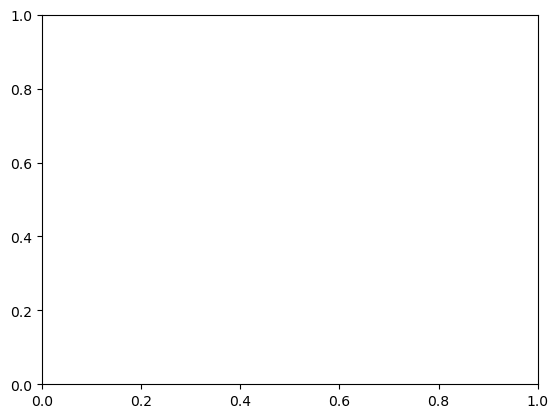

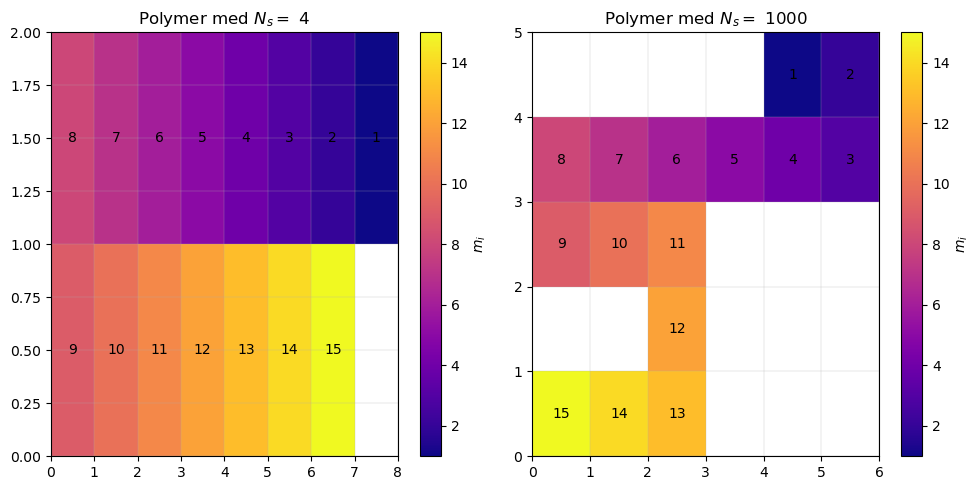

Antall vellykkede rotasjoner med N_s = 4: 3
Antall vellykkede rotasjoner med N_s = 1000: 597


In [21]:
# Test rotation of polymers (length 15), with 4 and 1000 rotations
N = 15
N_1, N_2= 4, 1000
polymer_1, c1 = rotate_test(N, N_1, rotate) # 4 rotations
polymer_2, c2 = rotate_test(N, N_2, rotate) # 1000 rotations
np.savez("polymer_data.npz", polymer_data=[polymer_1, polymer_2]) # Saves the polymers for later use

ax = plt.gca()

# Plot of polymers
fig, axs = plt.subplots(1,2, figsize=(10, 5))
plot(axs[0], polymer_1)
axs[0].set_title(f'Polymer med $N_s = $ {N_1}')

plot(axs[1], polymer_2)
axs[1].set_title(f'Polymer med $N_s = $ {N_2}')
axs[1].set_facecolor('pink')
plt.tight_layout()
plt.show()

print(f'Antall vellykkede rotasjoner med N_s = 4: {c1}')
print(f'Antall vellykkede rotasjoner med N_s = 1000: {c2}')

Forskjellen på to polymerene viser at polymeren som er forsøkt å bli rotert 1000 ganger har flere rotasjoner, som man kan forvente. Samtidig har ikke den andre polymeren blitt helt kveilet sammen til tross for alle rotasjonsforsøkene.

Polymeren var i utgangspunktet fremstilt i en NxN-matrise, bestående av 0-ere i alle posisjoner det ikke befant seg en monomer.

In [ ]:
def init_polymer_grid(N):
    grid = np.zeros((N, N), dtype=int)          # NxN grid with zeros
    grid[int(N / 2)] = np.arange(1, N + 1)      # Add polymer of N length in the middle of NxN grid
    return grid

For hver rotasjon tok funksjonen inn en NxN-matrise, lokaliserte alle ikke-null-elementer ved hjelp av np.argwhere()-funksjonen, brukte den samme tilnærmingen for å rotere matrisen som vi har gjort nå, for deretter å returnere den roterte polymeren i en NxN-matrise igjen.

For å kutte kjøretiden mest mulig vil man fjerne alle unødvendige steg. Hvorvidt det er nødvendig å kun rotere den korteste delen for å maksimere antall gyldige rotasjoner er derfor også interessant å se på. Vi definerer derfor den nye rotasjonsfunksjonen til å rotere alle etterfølgende monomerer istedenfor å sjekke hvilken lengde som er kortest.

In [ ]:
def rotate_grid(polymer, coord, direction):
    rotated_polymer = np.copy(polymer)
    N = len(rotated_polymer)

    i, j = coord[0], coord[1]

    # definerer om rotasjonen skal skje for verdiene over eller under mrot.
    lower_vals = False

    mrot = rotated_polymer[i, j]

    if mrot <= int(
        N / 2
    ):  # for mrot i midten vil den rotere monomerer med lavere nummer.
        lower_vals = True

    if lower_vals:  # lokaliserer monomerer som skal roteres
        vectors = np.argwhere(np.logical_and(rotated_polymer > 0, polymer < mrot))
    else:
        vectors = np.argwhere(rotated_polymer > mrot)

    if (
        direction
    ):  # lager rotasjonsmatrise, bytter om på x- og y-akse for å passe iterering gjennom 2D-array
        rot_matrix = np.matrix("0, -1; 1, 0")
    else:
        rot_matrix = np.matrix("0, 1; -1, 0")

    for vector in vectors:
        i, j = vector[0], vector[1]

        val = rotated_polymer[i, j]
        rotated_polymer[i, j] = 0
        rel_coord = vector - coord
        rot_rel_coord = np.dot(rot_matrix, rel_coord)
        new_coord = rot_rel_coord + coord
        new_i, new_j = new_coord[0, 0], new_coord[0, 1]
        rotated_polymer[new_i, new_j] = val

    return polymer, rotated_polymer

For å sjekke om matrisen var intakt måtte funksjonen iterere gjennom hele funksjonen, og sjekke nabo-koordinatene, over, under og de to sidene, manuelt for hver monomer. Det krevde en dobbel løkke, som ved stor N resulterte i lang kjøretid.

In [ ]:
def is_intact_grid(polymer, N):
    counter = 0
    pol_arr = []
    length = False
    val = False
    pol_len = len(polymer)
    neighbour_1 = False
    neighbour_2 = False
    neighbour_3 = False
    try:
        for i in range(pol_len):
            for j in range(pol_len):
                if polymer[i,j] != 0:
                    counter += 1
                    pol_arr.append(polymer[i,j])
                    if polymer[i,j] == 1:
                        if (polymer[i - 1,j] == 2 or polymer[i + 1,j] == 2 or
                        polymer[i,j - 1] == 2 or polymer[i,j + 1] == 2):
                            neighbour_1 = True
                    elif polymer[i,j] == N:
                            if (polymer[i - 1,j] == N-1 or polymer[i + 1,j] == N-1 or
                            polymer[i,j - 1] == N-1 or polymer[i,j + 1] == N-1):
                                neighbour_2 = True
                    else:
                        if (polymer[i,j] == 1 + polymer[i - 1,j] or polymer[i,j] == 1 + polymer[i + 1,j] or
                        polymer[i,j] == 1 + polymer[i,j - 1] or polymer[i,j] == 1 + polymer[i,j + 1]) and (polymer[i,j] == -1 + polymer[i - 1,j] or polymer[i,j] == -1 + polymer[i + 1,j] or
                        polymer[i,j] == -1 + polymer[i,j - 1] or polymer[i,j] == -1 + polymer[i,j + 1]):
                            neighbour_3 = True
        if counter == N:
            length = True
        delete_arr = set(pol_arr)
        if len(delete_arr) == len(pol_arr):
            val = True
        if (length and val and neighbour_1 and neighbour_2 and neighbour_3):
            return True

        else:
            return False
    except IndexError:
        return False

Når en polymer skal roteres mange ganger blir en matrise omgjort til vektorer, for så å bli utvidet igjen, Nf ganger. Dette istedenfor å holde seg i det todimensjonale vektor-arrayet, slik det gjør i oppgradert kode.

In [ ]:
def rotate_test_grid(N, Nf):
    c = 1
    temp_polymer = init_polymer_grid(N)
    for i in range(1, Nf):
        monomer = np.argwhere(temp_polymer > 0)
        coord = monomer[np.random.randint(0, N)]
        rot = random.randint(0, 1)
        old_polymer, rot_polymer = rotate_grid(temp_polymer,coord,rot)
        if is_intact_grid(rot_polymer, N):
            c += 1
            temp_polymer = rot_polymer
        else:
            temp_polymer = old_polymer
    return temp_polymer, c

Vi vil også finne hvilken operasjon som tar lengst tid å gjennomføre: Å sjekke hvilken ende av polymeren som er lengst legger inn en ekstra if-setning, men minker antall monomerer som skal roteres. For å sjekke kjøretid kan vi sammenlikne to rotasjonsfunksjoner hvor den ene alltid roterer etterfølgende verdier, og den andre sjekker mest gunstig side.

In [ ]:
def rotate_trailing(polymer, xy, state):
    rotation_matrix = np.array([[0, 2 * state - 1],[1 - 2 * state, 0]]) # Rotational matrix ( https://en.wikipedia.org/wiki/Rotation_matrix )
    monomer = np.where((polymer[:,0] == xy[0]) & (polymer[:,1] == xy[1]))[0][0] # Find monomer at position (x, y)
    relative_position = polymer[monomer:] - xy # Relative position to the part of the polymer that is to be rotated
    polymer[monomer:] = (relative_position @ rotation_matrix) + xy # add rotated polymer
    return polymer

In [ ]:
# Time of different rotatefunctions
print(f'Tid brukt i 2D:')
%timeit rotate_test(35, 5000)
print(f'Tid brukt i grid:')
%timeit rotate_test_grid(35, 5000)
print(f'Tid brukt i 2D (etterfølgende roteres):')
%timeit rotate_test(35, 5000, rotate_trailing)

Med mange rotasjoner bruker altså grid-funksjonene betydelig lenger kjøretid. De to ulike rotate-funksjonene har ingen betydelig forskjell i kjøretid, men kan bli relevant når energien til polymeren er med å bestemme rotasjonene.

In [ ]:
N_array = np.arange(10, 500, 10) # Polymer lengths
t_array = np.array(()) # Runtime array for increasing polymerlength N

# Testing polymerslengths with rotation-tests
for n in N_array:
  t_start = time.time()
  _, c = rotate_test(n, 1000)
  t_end = time.time()
  t_array = np.append(t_array, t_end-t_start)


# Plot of polymerlength vs time
plt.plot(N_array, t_array, label='Tid-verdier')
plt.grid()
plt.legend()
plt.title('Kjøretid vs polymerlengde')
plt.xlabel('N')
plt.ylabel('Tid[s]')


Grafen har noen hopp, men vi ser på trenden for konkudere med at kjøretiden øker med størrelsen på polymeren.

In [ ]:
def test_valid_rotations():
    # Define the range of polymer lengths (N)
    N = np.arange(10, 101, 10)

    # Define the values for Nf (number of rotations)
    Nf_values = [10, 100, 500, 750, 1000]

    # Plott
    fig, ax = plt.subplots(figsize=(8, 5))

    # Iterate over each Nf value
    for Nf in Nf_values:
        p_Nf = []
        # Calculate the percentage of valid rotations for each N
        for i in N:
            _, c = rotate_test(i, Nf)
            p_Nf.append((c/Nf)*100)
        # Plot the percentage of valid rotations for the current Nf value
        ax.plot(N, p_Nf, label=f'Nf = {Nf}')
    ax.set_xlabel('N')
    ax.set_ylabel('Gyldige rotasjoner [%]')
    ax.set_title('Gyldige rotasjoner vs polymerlengde')
    ax.grid()
    ax.legend()
    plt.show()


test_valid_rotations()

Ved flere forsøkte rotasjoner har prosentandelen gyldige rotasjoner en nedadgående trend når polymerlengden N øker. For liten $N_s$ er det såpass få rotasjoner som skal gjennomføres at det faktisk er en markant sannsynlighet for å unngå kollisjoner i det hele tatt. $N_f = 10$ viser dette, hvor det er vilkårlig om feilkveiling oppstår eller ikke. Kontrasten i prosent-variasjon i grafene skyldes vektingen av hver rotasjon: En ugyldig rotasjon vil senke prosentandelen $p =\frac{rotasjon}{N_f}$ mye mer når $N_f$ er mindre.

Når polymeren er stor er det større sannsynlighet for at rotasjonen forårsaker kollisjon mellom monomerer. Endene blir lange, antall monomerer som kan roteres om øker, og alle rotasjonsmulighetene gjør at polymeren kan låse seg fast i ugunstige konfigurasjoner.
Antall mulige rotasjoner går altså opp i takt med $N$, samtidig som gyldige rotasjoner minker. $p$ blir derfor mindre.
Dette gjenspeiles også i grafen, som synker med økende N for $N_f$ større enn omtrent 100.

Definerer en isotrop potensialmatrise med $V_{mn} = -1$ for alle verdier som ikke befinner seg på diagonalen eller over- og underdiagonalen.

In [ ]:
def matrixV(N,a=1):
    return np.array([[-a if (j < i - 1) or (j > i + 1) else 0 for j in range(N)] for i in range(N)])# N: size of V (N x N), a: constant

For å beregne energien til polymeren brukes først potensialmatrisen $V$ til å bestemme verdien på vekselvirkningen mellom to ulike monomerer. Deretter defineres en $b_{mn}$ som har verdien 1 dersom to monomerer er naboer og 0 ellers. Indreproduktet mellom potensialmatrisen og operatoren $b_{mn}$ gir styrken og lokasjonen til alle svake bindinger inni polymeren. Summen av matriseelementene gir den totale energien av alle vekselvirkningene.

\begin{equation}
  E = \frac{1}{2}\Sigma_{mn}^N V_{mn} b_{mn}
\end{equation}



In [ ]:
# function that returns the total energy of one specific polymer structure
def energy(polymer, V):
    b = distance.cdist(polymer, polymer, 'euclidean') # euclidian distance between every individual monomer in the polymer
    b[b > 1] = 0 # If every length is above 1, its not a neighbouring monomer, which makes the operator b = 0
    E = 1/2*np.sum(V*b) # the sum of all the valid interactions between the monomers
    return E

In [ ]:
# Load the data back from the NPZ file
data = np.load("polymer_data.npz")

# Retrieve the polymer array using the same keyword used for saving
polymer_1, polymer_2 = data['polymer_data']


N = 15
V_e = matrixV(N)
E_1 = energy(polymer_1, V_e) # Energy of polymer with length 15 and 4 rotations
E_2 = energy(polymer_2, V_e) # - 1000 rotations

print(f'Energi i polymer med N = 15 og 4 rotasjoner: {E_1}')
print(f'Energi i polymer med N = 15 og 1000 rotasjoner: {E_2}')



# Plot of polymers
fig, axs = plt.subplots(1,2, figsize=(10, 5))

plot(axs[0], polymer_1)
axs[0].set_title(f'polymer 1 med $E = {E_1}$ ')

plot(axs[1], polymer_2)
axs[1].set_title(f'polymer 2 med $E = {E_2}$ ')

plt.tight_layout()
plt.show()


At polymeren som har forsøkt å rotere 1000 ganger har lavest energi er som forventet. Jo flere rotasjoner, jo mer sammenkveilet blir polymeren. Å havne i en konfigurasjon som minker energien krever mange rotasjonsforsøk ettersom polymeren ofte kolliderer inn i seg selv når monomerer uten kovalent binding havner såpass tett. Ved 1000 forsøk vil polymeren ha flere muligheter til å skape vellykkede rotasjoner som danner svake bindinger, og dermed frigir energi.

Definerer metropolisalgoritme som sørger for at en polymer vil søke lavere energi.

In [ ]:
def metropolis(polymer, V, Ns, T):
    """
    Utfører Metropolis Monte Carlo-simulering for polymerfolding.

    Args:
        polymer (numpy.ndarray): En array som representerer polymeren.
        V (numpy.ndarray): En array som representerer potensialet.
        Ns (int): Antall Monte Carlo-steg som skal utføres.
        T (float): Temperaturen i systemet.
        beta (float, optional): Invers temperatur*boltzmann konstant

    Returns:
        numpy.ndarray: En array med energiverdiene for hvert Monte Carlo-steg.
    """
    k_b = 1.380649e-23  # Boltzmann constant
    beta = 1 / (k_b * T)  # Termodynamic beta
    N = len(polymer)
    E, D = np.zeros(Ns + 1), np.zeros(Ns + 1)  # Energy- and Distance-Array
    e, d = energy(polymer, V), 0  # Initalize e: energy, d: distance og
    i = 0  # i: counter/montecarlo-step
    while i < Ns:
        xy, state = polymer[np.random.randint(1, N - 1)], random.randint(0, 1)
        polymer_temp = np.copy(polymer)
        if intact(rotate(polymer_temp, xy, state), N):
            t_c = time.time()
            i += 1
            e_new = energy(polymer_temp, V)
            if (e_new < e):
                polymer = polymer_temp
                d = np.max(distance.cdist(polymer, polymer, "euclidean"))
                e = e_new
            elif (np.random.random() < np.exp(-beta * (e_new - e))):
                polymer = polymer_temp
                d = np.max(distance.cdist(polymer, polymer, "euclidean"))
                e = e_new
            E[i], D[i] = e, d
    return polymer, (E, D)

In [ ]:
N, Ns = 30, 5000 # length and total Monte Carlo-steps

p0 = init_polymer(N)

T_lav = np.random.randint(50, 100) # Low temperature in low interval
T_hoy = np.random.randint(293, 373) # High temperature in high interval

c1 = 4e-21 # potential constant for V
V0 = matrixV(N, c1) # Potential
polymer_lav, (E_lav, D_lav) = metropolis(p0, V0, Ns, T_lav) # Monte Carlo-simulation for low T
polymer_hoy, (E_hoy, D_hoy) = metropolis(p0, V0, Ns, T_hoy) # Monte Carlo-simulation for high T


# Plot
fig, axs = plt.subplots(2, 2, figsize=(10,10))

# Plot polymer for low temperature
plot(axs[0, 0], polymer_lav)
axs[0, 0].set_title(f'Lav Temperatur ($T_{{lav}} = {T_lav}$)')
axs[0, 0].grid(True)

# Plot polymer for high temperature
plot(axs[0,1], polymer_hoy)
axs[0, 1].set_title(f'Høy temperatur ($T_{{hoy}} = {T_hoy}$)')
axs[0, 1].grid(True)

# Plot E for low temperature
axs[1, 0].plot(E_hoy, label=f'T={T_hoy}K')
axs[1, 0].plot(E_lav, label=f'T={T_lav}K')
axs[1, 0].set_title(f'Energi (Lav T) vs Energi (Høy T)')
axs[1, 0].set_xlabel(f'$\\Delta MC(steg)$')
axs[1, 0].set_ylabel(f'$E[J]$')
axs[1, 0].legend()
axs[1, 0].grid()

# Plot D for low temperature
axs[1, 1].plot(D_hoy, 'purple', label=f'T={T_hoy}K')
axs[1, 1].plot(D_lav, 'g', label=f'T={T_lav}K')
axs[1, 1].set_title(f'Distanse (Lav T) vs Distanse (Høy T)')
axs[1, 1].set_xlabel(f'$\\Delta MC(steg)$')
axs[1, 1].set_ylabel(f'$d$')
axs[1, 1].legend()
axs[1, 1].grid()

plt.tight_layout()
plt.show()


Ser tydelig forskjell mellom grafene ved høy og lav temperatur. En fellesnevner er at begge polymerer vil strebe etter å minimere egen energi, som kommer tydeligst frem i polymeren med lav energi.
Fysisk sett er sannsynligheten for tilfeldige, ugunstige rotasjoner større ved høyere temperatur.
I koden simuleres dette stokastisk. Ved høy temperatur vil $\beta = \frac{1}{k_bT}$ bli liten, som igjen fører til at $e^{-\beta\Delta E}$ blir stor/nærmere 1, relativt til ved lav temperatur.
Når eksponensialleddet er nærmere 1 vil den tilfeldige $p$-en mest sannsynlig være mindre, og en rotering mot høyere energinivå kan forekomme.

Grafen for polymeren i høy temperatur viser den høyfrekvente fluktueringen, men også polymerens tendens til å rotere mot lavere energi.
Grafen har plutselige hopp, som raskt synker ved at polymeren roteres mot lavere energitilstand.
Polymeren ved lavere energi kan også oppleve ugunstige rotasjoner, men dette oppstår kun et fåtall av ganger. Garfen viser at energien
stabiliserer seg ved en viss verdi, et lokalt minimum. På grunn av strukturen når ikke polymeren en lavere energitilstand, selv om den ikke har nådd et globalt minima.
Den eksakte energiverdien kommer til å variere avhengig av hvordan polymeren kveiler seg, ettersom den kan "låse seg fast" i både energirike og energifattige konfigurasjoner.
Ved høy temperatur vil ikke verdien stabilisere seg på samme måte, men bunnpunktene av grafen går igjen, som tyder på at dette er minimumsenergien dersom de tilfeldige fluktueringene ikke hadde oppstått.

Nederst til høyre er også diameteren til polymeren for høy og lav tempratur plottet som funksjon av antall Monte Carlo-steg. På samme måte som for energien opplever høy temperatur hyppigere svingninger. På grunn av de tilfeldige rotasjonene vil ikke polymerene låse seg fast i en sammenkveilet struktur.

Definerer en ny symmetrisk potensialmatrise som minker i verdi nedover mot høyre i matrisen.

In [ ]:
def matrixV_symmetric(N, a=1):
    return np.array([[-a*(i+j) if (j < i - 1) or (j > i + 1) else 0 for j in range(N)] for i in range(N)])

# Create symmetrically scaled V matrix with size N_v
N_v = 15
V0 = matrixV_symmetric(N_v)

# Plot V matrix
fix, ax = plt.subplots()
ax.matshow(V0, cmap='summer')
for i in range(N_v):
  for j in range(N_v):
    c = V0[i, j]
    if c != 0:
      ax.text(j, i, str(int(c)), va="center", ha="center", color="white")



Siden polymeren søker mot lavest mulig energi vil monomerer alltid søke å vekslvirke med monomerene i et lavere potensial, altså de med høyere indeks. Monomerene med lav indeks vil derfor søke monomerer med høyere indeks, samtidig som monomerer med høy indeks vil helst vekselvirke med andre hoyindekserte monomerer. Man kan derfor forvente at endemonomeren vil vekselvirke med en annen monomer nært enden, og første monomer vil vekselvirke med monomer av høyere indeks.

In [ ]:
N, Ns = 30, 10000 # length polymer and total MC-steps
p0 = init_polymer(N)
V_decreasing = matrixV_symmetric(N, c1)

# Polymers with scaled V matrix
polymer_decreasing_tlav, (E_decreasing_tlav, D_decreasing_tlav) = metropolis(p0, V_decreasing, Ns, T_lav)
polymer_decreasing_thoy, (E_decreasing_thoy, D_decreasing_thoy) = metropolis(p0, V_decreasing, Ns, T_hoy)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('Energi (minkende potensial ved lav og høy temperatur)', fontsize=12)

# plot Polymer
# decreasing potential and low T
plot(axs[0], polymer_decreasing_tlav)
axs[0].set_title('Polymer 1: Lav T')
axs[0].grid(True)

# decreasing potential and high T
plot(axs[1], polymer_decreasing_thoy)
axs[1].set_title('Polymer 2: Høy T')
axs[1].grid(True)


fig, axs = plt.subplots(1, 1)
# Plot energy
# decreasing potential and low T
axs.plot(E_decreasing_tlav, '-', label=f'T={T_lav}K', alpha=0.7, linewidth=1.5)
axs.plot(E_decreasing_thoy, '-', label=f'T={T_hoy}K', alpha=0.7, linewidth=1.5)
axs.set_xlabel('M.C-Steg')
axs.set_ylabel(f'$E[J]$')
axs.set_title(f'Minkende potensial skalert med $-4e^-21(i+j)$')
axs.legend()
axs.grid(True)

plt.tight_layout()
plt.show()


For å avgjøre om polymeren kveiler seg som forventet tar vi utgangspunkt i polymeren som befinner seg lav temperatur. I høy temperatur vil rotasjonene, som før, foregå mer stokastisk. Ser at monomeren med lav indeks forsøker å vekselvirke med de av høyere indeks, samtidig som endemonomerene vekselvirker med hverandre.
Polymeren i høy temperatur vekselvirker også på samme måte. Energigrafene viser at denne oppnår en lavere energi, og i motsetning til tidligere har den ikke de samme hyppige svingningene. Den stabiliserer  seg også på et høyere energinivå enn i et isotropt potensial.

In [ ]:
def expected_value(T, N=25, Ex=1000, Ns=10000, a=1, task_h=0):
    # T: Temperature
    # N: Size of the polymer
    # Ex: Exclude the first 1000 MC steps
    # Ns: Number of Monte Carlo steps to perform
    # a: Potential energy constant

    V = matrixV(N, c1)  # isotropic V matrix
    E_exp, E_std = np.array([]), np.array([])  # Expected values <E> and standard deviation (sigma_e) Array
    D_exp, D_std = np.array([]), np.array([])  # Expected values of distance <D> and standard deviation (sigma_d) Array
    polymer = init_polymer(N)
    for t in T:  # Iterate through Temp array (Tf-Ti)/dT times
        if task_h == 0:
            polymer = init_polymer(N)
        _, (E, D) = metropolis(polymer, V, Ns, t)  # Energy of polymer with 1000-> Ns steps
        E_exp, E_std = np.append(E_exp, np.mean(E[Ex:])), np.append(E_std, np.std(E[Ex:]))
        D_exp, D_std = np.append(D_exp, np.mean(D[Ex:])), np.append(D_std, np.std(D[Ex:]))
    return (E_exp, E_std), (D_exp, D_std)

In [ ]:
# Parameters
Ti, Tf, dT = 10, 1000, 30 # Temperature interval
N, Ex, Ns1, Ns2 = 30, 1000, 5000, 1200 # Polymer length, exclude 1000 first MC steps, MC steps
c1 = 4e-21  # constant for V

T = np.arange(Ti, Tf, dT)  # Temperatures
Estat1, Dstat1 = expected_value(T, N, Ex, Ns1, c1)  # Expected Energy and Distance
Estat2, Dstat2 = expected_value(T, N, Ex, Ns2, c1)  # Expected Energy and Distance



# Plot
fig, axs = plt.subplots(1, 2, figsize=(12,4))
fig.suptitle('Forventet energi vs Temperatur', fontsize=16)

# Plot E for isotropic potential with 5000 MC steps
axs[0].errorbar(T, Estat1[0], yerr=Estat1[1], fmt='o', label=f'$\\langle E \\rangle$, $Ns_2 = {Ns2}$')
axs[0].set_xlabel('T[K]')
axs[0].set_ylabel(f'$E[J]$')
axs[0].legend()
axs[0].grid()

# Plot E for isotropic potential with 1200 MC steps
axs[1].errorbar(T, Estat2[0], yerr=Estat2[1], fmt='go', label=f'$\\langle E \\rangle$, $Ns_1 = {Ns1}$')
axs[1].set_xlabel('$T[K]$')
axs[1].set_ylabel(f'$E[J]$')
axs[1].legend()
axs[1].grid()


# Plot D for isotropic potential
fig, axs = plt.subplots(figsize=(5, 4))
fig.suptitle(f'Forventet distanse vs Temperatur', fontsize=12)
axs.errorbar(T, Dstat1[0], yerr=Dstat1[1], fmt='co', label=f'$\\langle d \\rangle$, $Ns_1 = {Ns1}$')
axs.set_xlabel('$T[K]$')
axs.set_ylabel(f'$d$')
axs.legend()
axs.grid()

plt.tight_layout()
plt.show()

Ut i fra plottet ser det ut til at forventingsverdien til energien har større spredning ved høyere temperatur. Dette er fordi den høye temperaturen er mer preget av tilfeldige fluktuasjoner, og tillater flere rotasjoner, hvor bindinger brytes og dannes med jevne mellomrom. Ved lavere temperatur kan vi observere et lavere standardavvik. Forventningsverdien øker også i takt med temperaturen, som kan forklares av at flere bindinger brytes ved høy temperatur.

Diameteren til polymeren øker med økende temperatur, som går overens med at stoffer vanligvis utvider seg ved oppvarming.

In [ ]:
T_min = np.argmin(Estat1[0]) # index where temperature is lowest
t_min = T[T_min] # Actual lowest temperature

print(f'Minimum forventet energi: {Estat1[0][T_min]}J ved T={t_min}K')
print(f'Minimum forventet distanse: {Dstat1[0][T_min]} ved T={t_min}K')


Bruker den laveste temperaturen fra de forrige målingene til å se nøyere på energien til polmeren som funksjon av Monte-Carlo-steg.

In [ ]:
N, Ns = 30, 6000
Ex = 1000 # 'Exlude from' values
Nt = 10 # Number of simulations of the low temperature
c1 = 4e-21

p0 = init_polymer(N)
V0 = matrixV(N, c1)
MC = np.arange(Ex, Ns+1) # Monte-carlo steps
E_array = np.zeros(Ns)  # array for <E> and std/sigma_e

# Run and plot the MC simulation
fig, axs = plt.subplots(1, 1, figsize=(14, 8))

for t in range(Nt):
    _, (E_tlav, _) = metropolis(p0,V0,Ns,t_min)
    axs.plot(MC, E_tlav[Ex:], '-', label=f'$Sim: {t + 1}$', linewidth=1)

axs.set_title(f'Forventet Energi vs Temperatur (T = {t_min}) ')
axs.set_ylabel(f'E[J]')
axs.set_xlabel(f'$\\Delta MC$')
axs.legend()
axs.grid()

plt.tight_layout()
plt.show()

Ved lavere temperaturer er som oftest standardavviket lavere, og gir derfor det mest eksakte bilde på energien til polymeren.
Plottet illustrerer også tydeligere vektingen av forventningsverdien til energien ved den laveste temperaturen. De horisontale linjene viser til lokale minima, med svingninger til andre energitilstander. Den nederste linjen kan tolkes som det globale minimum, hvor polymeren ikke lenger kan minimere energien sin. Stor ansamlingen av vertikale linjer forteller at polymeren veksler hypping mellom diskretiserte energinivå.

Ser at intervallet
\begin{equation}
E \in [-6.0 \cdot 10^{-20}, -6.8 \cdot 10^{-20}] J
\end{equation}
inneholder energitilstandene som er mest besøkt. Grafen viser et mer nøyaktig bilde på hvilken energitilstand polymeren gjennomsnittlig er ved lave temperaturer, enn ved $\langle E \langle(T)$ ved mange temperaturer.

In [ ]:
# Constant parameters for the last simulations
N, Nf, Ns = 30, 1000, 10000
c_g = np.random.uniform(2,6)*1e-21

In [ ]:
# Temperature interval
Ti, Tf, dT = 10, 1000, 30
T_g = np.arange(Ti, Tf, dT)

t0 = time.time() # Start time
# Expected energy and distance
Estat_g, Dstat_g = expected_value(T_g, N, Nf, Ns, c_g)

# Print runtime and parameters
print(f'c_g: {c_g}', ', N:', N, ', Nf:', Nf, ', Ns:', Ns)
print(f'Kjøretiden til expected_value er:\n', time.time()-t0,' sek') # For a more detailed runtime analysis use: %timeit expected_value(T_g, N, Nf, Ns, c_g)


# Plot for <D> and T increasing
fig, axs = plt.subplots(1, 1)

axs.plot(T_g, Dstat_g[0],'-ro', label=f'$<d>(T)$')
axs.set_title(f'Forventet Distanse vs Temperatur')
axs.set_xlabel(f'$T [K]$')
axs.set_xticks(T_g, minor=True)
axs.set_ylabel(f'$d$')
axs.legend()
axs.grid()

plt.tight_layout()
plt.show()



T_min_g = [np.argmin(Estat_g[0])] # Temperature for minimal expected energy

print(f'Minimum forventet energi: {Estat_g[0][T_min_g]}J ved T={T_g[T_min_g]}K')
print(f'Minimum forventet distanse: {Dstat_g[0][T_min_g]} ved T={T_g[T_min_g]}K')


På samme måte som temperaturen vil diameteren til polymeren øke i takt med temperaturen. Høyere temperatur vil si at det er større sannsynligheten for færre svake bindinger, som igjen resulterer i høyere energi. Dermed vil også forventningsverdien til diamereren bli større ettersom polymeret er mer utstrukket med færre bindinger.

In [ ]:
# Parameters for polymer and simulation
# Temperature
Ti, Tf, dT = 1000, 10, -30
T_h = np.arange(Ti, Tf, dT)

# expected energy and distance (opppgave h)
Estat_h, Dstat_h = expected_value(T_h, N, Nf, Ns, c_g, 1)

# Print parameters
print(f'c_h: {c_g}', ', N:', N, ', Nf:', Nf, ', Ns:', Ns)

# Plot D for increasing/decreasing temperature
fig, axs = plt.subplots(1, 1)

axs.plot(T_h, Dstat_h[0], '-bo', label=f'$\\langle d \\rangle (T)$ - T minker')
axs.plot(T_g, Dstat_g[0], '-ro', label=f'$\\langle d \\rangle(T)$ - T øker')
axs.set_title(f'Forventet Distanse vs Temperatur')
axs.set_xlabel('T[K]')
axs.set_xticks(T_h, minor=True)
axs.set_ylabel(f'$d$')
axs.legend()
axs.grid()

plt.tight_layout()
plt.show()


T_min_h = [np.argmin(Estat_h[0])]
print(f'Minimum forventet energi: {Estat_h[0][T_min_h]}J ved T={T_h[T_min_h]}K')
print(f'Minimum forventet distanse: {Dstat_h[0][T_min_h]}m ved T={T_h[T_min_h]}K')

Når T øker vil polymeren gå tilbake til en rett konfigurasjon for hvert temperatursteg. For lave temperaturer er ikke dette nødvendigvis en dårlig tilnærming, ettersom den ikke er rotert like mye. Når temperaturen øker vil også de stokastiske rotasjonene oppstå oftere. Tidligere målinger viser at høyere temperatur tilsvarer høyere forventet energi på grunn av at bindingene frigir energi når de oppløses. På samme måte vil diameteren til polymeren øke i takt med høyere temperatur. Å iterere gjennom på denne måten sørger for å få med energien til lav-temperatur-konfigurasjonene. Dette tilsvarer en nedkjølingsprosess.

For synkende temperatur er det stor sannsynlighet for at polymeren låser seg fast i en høy-temperatur-konfigurasjon fordi den henter polymeren fra forrige energinivå og fortsetter å forsøke å rotere den i det nye temperaturnivået. En polymer som er rotert fra før er en mer nøyaktig fremstilling av hvordan polymerer opptrer i praksis ved høy temperatur.

Selvom de to grafene er tilnærmet like kan man konkludere med at de to metodene representerer polymeren best i ulike situasjoner. Ved nedkjøling, slik gjort i oppgave 2h), være den beste metoden for å observere polymerens oppførsel i lav temperatur. Oppvarmingsmetoden brukt i oppgave 2g) vil imidlertid representere polymeren bedre i høy temperatur.